       IMAGE PIXEL MANIPULATOR USING NUMPY

STEP 1: IMAGE CREATION
Image shape: (200, 200, 3)
Image data type: uint8


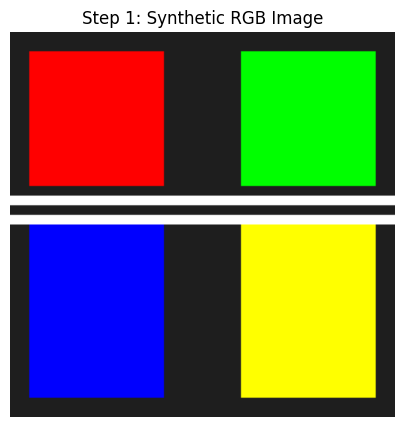


STEP 2: DRAWING SHAPES AND STRIPES


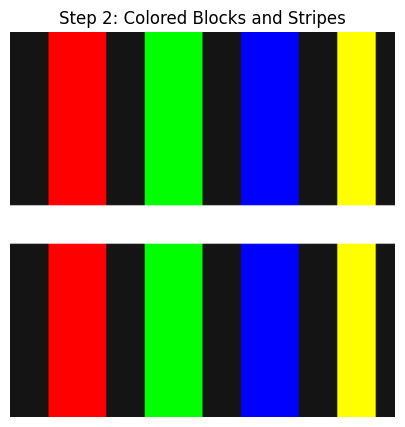


STEP 3: CROPPING AND FLIPPING
Original image shape: (200, 200, 3)
Cropped image shape: (160, 160, 3)
Vertical flip shape: (200, 200, 3)
Horizontal flip shape: (200, 200, 3)


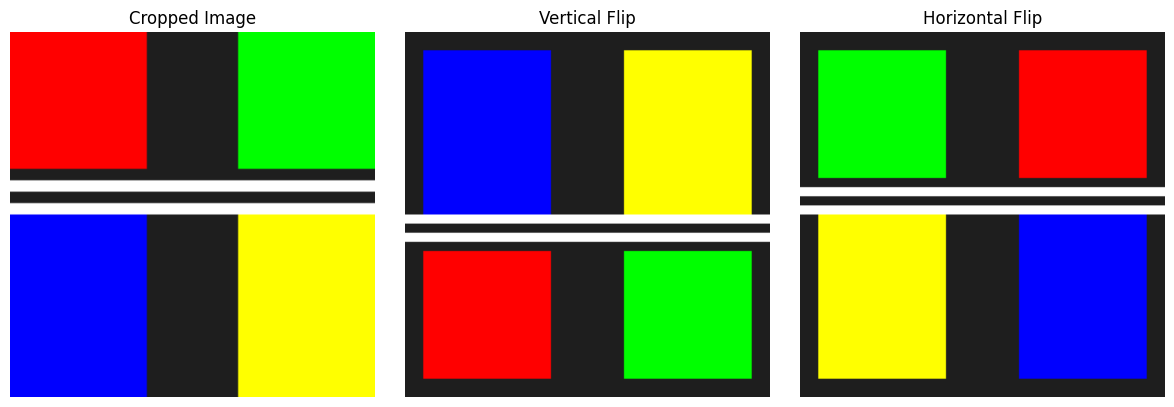

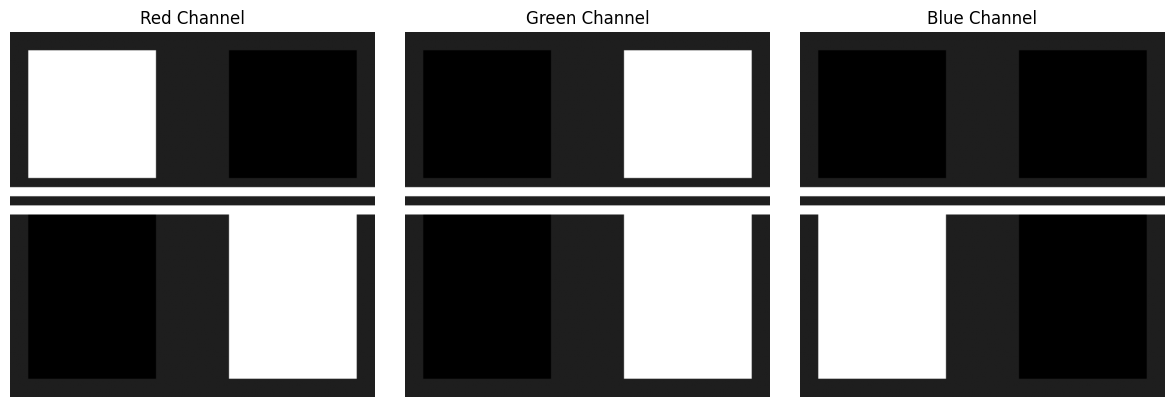


STEP 4: BRIGHTNESS ADJUSTMENT
Number of pixels selected by mask: 13200


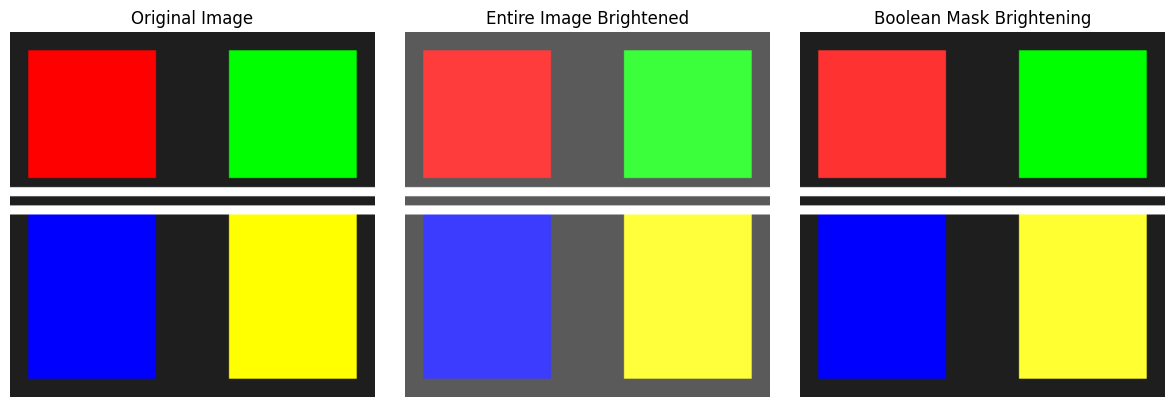


STEP 5: MEMORY COMPARISON
uint8 image
Data type: uint8
Memory in bytes: 120000
Memory in KB: 117.1875

float32 image
Data type: float32
Memory in bytes: 480000
Memory in KB: 468.75

Memory ratio (float32 / uint8): 4.0


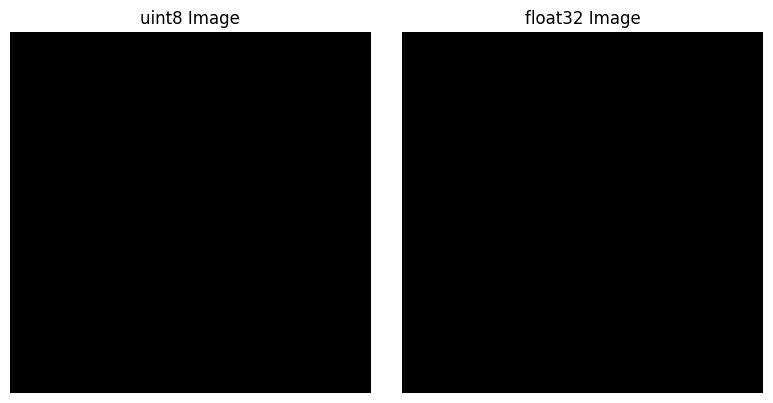


BONUS: IMAGE USING np.full()


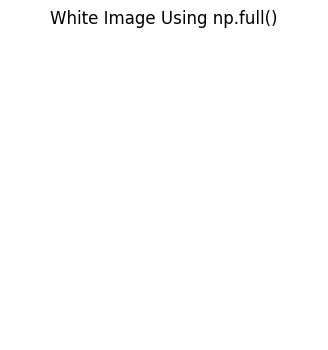


PROJECT COMPLETED SUCCESSFULLY!
NumPy concepts demonstrated:
1. np.zeros() and np.full()
2. 3D arrays and RGB channels
3. Array slicing and region filling
4. Cropping and negative-step slicing
5. RGB channel extraction
6. astype() and dtype conversion
7. Boolean masking
8. np.clip() for brightness control
9. Array memory comparison using nbytes


In [ ]:

import numpy as np
import matplotlib.pyplot as plt


# PROJECT 2: IMAGE PIXEL MANIPULATOR (SYNTHETIC IMAGES)


print("=" * 60)
print("       IMAGE PIXEL MANIPULATOR USING NUMPY")
print("=" * 60)

# STEP 1: CREATE A 200 x 200 RGB IMAGE

# Create a black image using NumPy zeros
# Shape = (height, width, RGB channels)
image = np.zeros((200, 200, 3), dtype=np.uint8)

print("\nSTEP 1: IMAGE CREATION")
print("Image shape:", image.shape)
print("Image data type:", image.dtype)

# Fill the background with a dark gray color
image[:] = [30, 30, 30]

# Draw a red rectangle
image[10:80, 10:80] = [255, 0, 0]

# Draw a green rectangle
image[10:80, 120:190] = [0, 255, 0]

# Draw a blue rectangle
image[100:190, 10:80] = [0, 0, 255]

# Draw a yellow rectangle
image[100:190, 120:190] = [255, 255, 0]

# Draw horizontal white stripes using slicing
image[85:90, :] = [255, 255, 255]
image[95:100, :] = [255, 255, 255]

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Step 1: Synthetic RGB Image")
plt.axis("off")
plt.show()



# STEP 2: CREATE AND FILL REGIONS USING SLICING

print("\nSTEP 2: DRAWING SHAPES AND STRIPES")

# Create another blank image
pattern = np.zeros((200, 200, 3), dtype=np.uint8)

# Fill the background with a dark color
pattern[:] = [20, 20, 20]

# Draw vertical colored stripes
pattern[:, 20:50] = [255, 0, 0]
pattern[:, 70:100] = [0, 255, 0]
pattern[:, 120:150] = [0, 0, 255]
pattern[:, 170:190] = [255, 255, 0]

# Draw a white horizontal stripe
pattern[90:110, :] = [255, 255, 255]

plt.figure(figsize=(6, 5))
plt.imshow(pattern)
plt.title("Step 2: Colored Blocks and Stripes")
plt.axis("off")
plt.show()



# STEP 3: CROP AND FLIP THE IMAGE


print("\nSTEP 3: CROPPING AND FLIPPING")

# Crop a section of the original image
cropped = image[20:180, 20:180]

# Flip vertically using negative-step slicing
vertical_flip = image[::-1, :, :]

# Flip horizontally using negative-step slicing
horizontal_flip = image[:, ::-1, :]

# Extract individual RGB channels
red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

print("Original image shape:", image.shape)
print("Cropped image shape:", cropped.shape)
print("Vertical flip shape:", vertical_flip.shape)
print("Horizontal flip shape:", horizontal_flip.shape)

# Display the crop and flipped images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cropped)
plt.title("Cropped Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(vertical_flip)
plt.title("Vertical Flip")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(horizontal_flip)
plt.title("Horizontal Flip")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display RGB channels separately
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(red_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Red Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(green_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Blue Channel")
plt.axis("off")

plt.tight_layout()
plt.show()



# STEP 4: BRIGHTNESS ADJUSTMENT USING BOOLEAN MASKING

print("\nSTEP 4: BRIGHTNESS ADJUSTMENT")

# Convert uint8 image to float32
float_image = image.astype(np.float32)

# Increase brightness by adding 60
bright_image = float_image + 60

# Clip pixel values to the valid range of 0 to 255
bright_image = np.clip(bright_image, 0, 255)

# Convert back to uint8
bright_image = bright_image.astype(np.uint8)

# Boolean mask: select pixels with a red channel greater than 100
mask = image[:, :, 0] > 100

# Create a copy so the original image remains unchanged
masked_image = image.copy()

# Brighten only pixels selected by the mask
masked_image[mask] = np.clip(
    masked_image[mask].astype(np.int16) + 50,
    0,
    255
).astype(np.uint8)

print("Number of pixels selected by mask:", np.count_nonzero(mask))

# Display brightness results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright_image)
plt.title("Entire Image Brightened")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(masked_image)
plt.title("Boolean Mask Brightening")
plt.axis("off")

plt.tight_layout()
plt.show()



# STEP 5: COMPARE UINT8 AND FLOAT32 MEMORY USAGE


print("\nSTEP 5: MEMORY COMPARISON")

# Create images with different data types
image_uint8 = np.zeros((200, 200, 3), dtype=np.uint8)
image_float32 = np.zeros((200, 200, 3), dtype=np.float32)

# Display memory information
print("uint8 image")
print("Data type:", image_uint8.dtype)
print("Memory in bytes:", image_uint8.nbytes)
print("Memory in KB:", image_uint8.nbytes / 1024)

print("\nfloat32 image")
print("Data type:", image_float32.dtype)
print("Memory in bytes:", image_float32.nbytes)
print("Memory in KB:", image_float32.nbytes / 1024)

print("\nMemory ratio (float32 / uint8):",
      image_float32.nbytes / image_uint8.nbytes)

# Display the images using Matplotlib
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_uint8)
plt.title("uint8 Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_float32)
plt.title("float32 Image")
plt.axis("off")

plt.tight_layout()
plt.show()



# BONUS: CREATE A WHITE IMAGE USING np.full()


print("\nBONUS: IMAGE USING np.full()")

# Create a white 100 x 100 RGB image
white_image = np.full((100, 100, 3), 255, dtype=np.uint8)

plt.figure(figsize=(4, 4))
plt.imshow(white_image)
plt.title("White Image Using np.full()")
plt.axis("off")
plt.show()



# PROJECT SUMMARY


print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("NumPy concepts demonstrated:")
print("1. np.zeros() and np.full()")
print("2. 3D arrays and RGB channels")
print("3. Array slicing and region filling")
print("4. Cropping and negative-step slicing")
print("5. RGB channel extraction")
print("6. astype() and dtype conversion")
print("7. Boolean masking")
print("8. np.clip() for brightness control")
print("9. Array memory comparison using nbytes")
